---
number-sections: false
execute:
  enabled: false
---

<!-- Keep the unnumbered chapter heading for book metadata. -->
# CAPM：Stata 完整实验 {.unnumbered}

[理论讲义](../../lectures/capm.qmd) · [数据说明](../../data/capm/README.md) · [项目仓库](https://github.com/lianxhcn/FinEco)

## 实验说明 {#sec-capm-lab .unnumbered}

理论讲义中的代码片段用于解释关键运算和图表来源；本 Notebook 将数据核对、估计、循环和绘图串成完整执行流程，读取同样的两份冻结输入。

本实验用同源美国十行业组合、市场超额收益与月度无风险收益，估计市场风险暴露和风险调整收益，再比较滚动窗口和已知参数的模拟。固定样本为 1990 年 1 月至 2025 年 12 月，共 432 个月。

收益单位为每月百分数，$\beta$ 无单位，$\alpha$ 的单位为每月百分数。Mkt-RF 已是超额收益，不能再减 RF。真实行业组合、市场代理和模拟分别说明，不与首讲 A 股篮子混用。

从 FinEco 根目录启用项目环境后运行 `python tools/capm/run_notebook.py`。运行器设置根目录、Stata 内核和图片时间戳，从第一个单元开始执行；不依赖旧电脑或先前交互状态。本页保存实际输出，网页渲染不取数、不执行代码。

图形部分单列 `%set graph_height` 显示设置，只控制本 Notebook 的画布高度；随后执行的 Stata 代码与 `capm.do` 一致，不修改全局配置或估计条件。

两个固定输入为 [industry_monthly.dta 的说明](../../data/capm/industry_monthly-README.md) (真实行业数据) 和 [beta_sim.dta 的说明](../../data/capm/beta_sim-README.md) (教学模拟)。各次分析只读这两份数据；本地重跑所需文件见 [运行说明](../../tools/capm/README.md)，仓库中的通用入口见 [notebooks 目录](https://github.com/lianxhcn/FinEco/tree/main/notebooks) 与 [tools 目录](https://github.com/lianxhcn/FinEco/tree/main/tools)。本页可以独立阅读已保存的代码与输出，重新执行仍需完整项目环境与输入。

结果整理使用 `estout` 包中的外部命令 `esttab`，首次使用前可在 Stata 运行 `ssc install estout`。本 Notebook 不自动安装或更新命令；开始前请用 `which esttab` 核对。参数表仍读取 `newey` 的 HAC(6) 估计，分别显示标准误、95% 置信区间，并导出 `logs/capm/regression.rtf`；RTF 可用 Word 打开。

## 模型与变量

记行业与市场的超额收益分别为 $r_{i,t}=R_{i,t}-R_{f,t}$ 和 $r_{m,t}=R_{m,t}-R_{f,t}$。其中 $i$ 表示行业，$t$ 表示月份，$R_{f,t}$ 为同月无风险收益。带截距的市场回归为

$$
r_{i,t}=\alpha_{i}+\beta_{i}r_{m,t}+\varepsilon_{i,t}.
$$

$\alpha_{i}$ 是截距，$\beta_{i}$ 衡量对市场共同波动的暴露，$\varepsilon_{i,t}$ 是单一市场因素未解释的随机干扰项。$\beta$ 是资产与市场超额收益协方差除以市场超额收益方差，不衡量资产的全部波动。CAPM 在相应均衡与稳定参数条件下增加零截距限制；能估出 $\beta$，不等于定价关系已成立。

实验依次核对数据、比较点估计与推断、观察行业差异、检查组合恒等式，最后比较滚动窗口和模拟真值。改变一个设置时，先说明其他哪些条件保持不变。


## 数据核对

先确认冻结输入、月份连续性、样本量和收益单位，再列出原始行业文件的前六行。mdate 是月份；hitec、utils 是尚未扣除无风险收益的行业收益；mktrf 已是市场超额收益；rf 是同月无风险收益。行业列减 rf 一次生成 ex_hitec、ex_utils，mktrf 不再扣减。所有收益列均以每月百分数存储。

In [1]:
version 19
clear all
set more off
set linesize 76
capture mkdir logs/capm
capture mkdir figs/raw
local root : environment FINECO_ROOT
if "`root'" != "" {
    cd "`root'"
}
local stamp : environment CAPM_RUN_STAMP
if "`stamp'" == "" {
    display as error "请从本章运行器启动以设置图片时间戳"
    exit 198
}
global CAPM_STAMP "`stamp'"
set scheme s2color
use data/capm/industry_monthly.dta, clear
format mdate %tm
tsset mdate, monthly
assert _N == 432
assert mdate == tm(1990m1) + _n - 1
* 前六行保留原始行业收益  mktrf 已扣 rf
list mdate hitec utils mktrf rf in 1/6, noobs
foreach a in nodur durbl manuf enrgy hitec telcm shops hlth utils other {
    generate double ex_`a' = `a' - rf
}
summarize mktrf rf ex_hitec ex_utils




Running D:\stata19/profile.do ...



D:\github_lianxh\FinEco


(US monthly returns in percent, 1990-2025)



Time variable: mdate, 1990m1 to 2025m12
        Delta: 1 month

  +--------------------------------------+
  |  mdate   hitec   utils   mktrf    rf |
  |--------------------------------------|
  | 1990m1   -1.47   -5.35    -7.8   .57 |
  | 1990m2    4.04     .21    1.12   .57 |
  | 1990m3    4.63    -.75    1.83   .64 |
  | 1990m4   -1.94   -5.52   -3.36   .69 |
  | 1990m5   12.41    5.43    8.43   .68 |
  |--------------------------------------|
  | 1990m6   -1.27     .75   -1.09   .63 |
  +--------------------------------------+

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
       mktrf |        432     .738588    4.389314      -17.2       13.6
          rf |        432    .2233796    .1873609          0        .69
    ex_hitec |        432    1.093843     6.68164     -26.45      20.31
    ex_utils |        432    .6063426        4.04     -13.17      11.16


## 估计与推断

先显示 ex_hitec 与 mktrf 的样本协方差矩阵 V，再用 V[1,2]/V[2,2] 算出斜率。V 的顺序与 correlate 中的变量顺序相同；它不是回归系数估计的方差矩阵 e(V)。相同样本与解释变量下，三种方差估计的 $\alpha$、$\beta$ 应相同，标准误可以不同。HAC 最大滞后 6 个月仅为本例教学选择，不是所有月度数据的固定规则。分别检验 $\alpha=0$ 和 $\beta=1$。

In [2]:
* 相同样本比较三种方差估计  点估计必须相同
* V 是两种超额收益的样本协方差矩阵  不是 e(V)
correlate ex_hitec mktrf, covariance
matrix V = r(C)
matrix list V
display "beta = " %7.3f (V[1,2] / V[2,2])
regress ex_hitec mktrf
estimates store conventional
regress ex_hitec mktrf, vce(robust)
estimates store robust
newey ex_hitec mktrf, lag(6)
estimates store hac6
estimates table conventional robust hac6, ///
    b(%9.4f) se(%9.4f) stats(N)
test _cons = 0
test mktrf = 1



(obs=432)

             | ex_hitec    mktrf
-------------+------------------
    ex_hitec |  44.6443
       mktrf |  25.3669  19.2661




symmetric V[2,2]
           ex_hitec      mktrf
ex_hitec   44.64431
   mktrf  25.366888  19.266073
beta =   1.317



      Source |       SS           df       MS      Number of obs   =       4
> 32
-------------+----------------------------------   F(1, 430)       =   1277.
> 21
       Model |  14395.2248         1  14395.2248   Prob > F        =    0.00
> 00
    Residual |  4846.47262       430  11.2708665   R-squared       =    0.74
> 81
-------------+----------------------------------   Adj R-squared   =    0.74
> 75
       Total |  19241.6974       431  44.6443096   Root MSE        =    3.35
> 72



----------------------------------------------------------------------------
> --


    ex_hitec | Coefficient  Std. err.      t    P>|t|     [95% conf. interva
> l]
-------------+--------------------------------------------------------------
> --


       mktrf |

... (5 outputs left out)


--------------------------------------------------
    Variable | convent~l    robust       hac6     
-------------+------------------------------------


       mktrf |    1.3167      1.3167      1.3167  


             |    0.0368      0.0468      0.0716  
       _cons |    0.1214      0.1214      0.1214  
             |    0.1638      0.1680      0.1842  
-------------+------------------------------------
           N |       432         432         432  
--------------------------------------------------
                                      Legend: b/se



 ( 1)  _cons = 0

       F(  1,   430) =    0.43
            Prob > F =    0.5102

 ( 1)  mktrf = 1

       F(  1,   430) =   19.55
            Prob > F =    0.0000


## 整理回归结果

先用 newey 估计并保存两个行业，再用 esttab 分别报告系数与标准误、系数与 95% 置信区间。它读取已保存的系数、方差和自由度，不改变估计方法。区间仍用自由度 430 的 $t$ 临界值，与后面的手动端点计算一致。最后导出 RTF 文件，便于继续整理实证结果。

In [3]:
* 外部命令只整理结果  标准误口径仍由 newey 决定
which esttab
quietly newey ex_hitec mktrf, lag(6)
estimates store capm_hitec
quietly newey ex_utils mktrf, lag(6)
estimates store capm_utils
esttab capm_hitec capm_utils, b(3) se(3) nostar
esttab capm_hitec capm_utils, b(3) ci(3) level(95) nostar
esttab capm_hitec capm_utils using "logs/capm/regression.rtf", ///
    replace b(3) se(3) nostar



D:/stata/plus\e\esttab.ado
*! version 2.1.1  10jun2022  Ben Jann
*! wrapper for estout


--------------------------------------
                      (1)          (2)
                 ex_hitec     ex_utils
--------------------------------------
mktrf               1.317        0.439
                  (0.072)      (0.056)

_cons               0.121        0.282
                  (0.184)      (0.179)
--------------------------------------
N                     432          432
--------------------------------------
Standard errors in parentheses



----------------------------------------------------------
                                (1)                    (2)
                           ex_hitec               ex_utils
----------------------------------------------------------
mktrf                         1.317                  0.439
                      [1.176,1.457]          [0.328,0.549]

_cons                         0.121                  0.282
                     [-0.241,0.483]         [-0.069,0.634]
----------------------------------------------------------
N                               432                    432
----------------------------------------------------------
95% confidence intervals in brackets


(output written to logs/capm/regression.rtf)


In [4]:
%set graph_height = 4.5in

## 行业比较

比较均值、波动、$\beta$ 与拟合优度的不同含义。下表各行业均用 432 个月、相同市场代理和 HAC(6) 口径。十个单独检验不等于联合模型检验，也未作多重检验校正。

(Note: Below code run with echo to enable preserve/restore functionality.)












  +---------------------------------------------------------------------+
  | industry |   mean |     sd |   alpha |   beta | se_beta |   p_alpha |
  |    nodur | 0.8481 | 3.8078 |  0.1655 | 0.6217 |  0.0467 | .25339347 |
  |---------------------------------------------------------------------|
  |                                     r2                              |
  |                              .51295126                              |
  +---------------------------------------------------------------------+

  +---------------------------------------------------------------------+
  | industry |   mean |     sd |   alpha |   beta | se_beta |   p_alpha |
  |    durbl | 1.1798 | 8.5376 | -0.0797 | 1.4028 |  0.0994 |  .7671453 |
  |---------------------------------------------------------------------|
  |                                     r2                              |
  |                              .51862495                              |
  +----------------------------

file logs/capm/estimates.csv saved




(file figs/raw/capm-fig02-betas-20261111-155412.png not found)


file figs/raw/capm-fig02-betas-20261111-155412.png written in PNG format

(file figs/raw/capm-fig02-betas-20261111-155412.svg not found)
file figs/raw/capm-fig02-betas-20261111-155412.svg saved as SVG format



file figs/raw/capm-fig02-betas-20261111-155412.pdf saved as PDF format





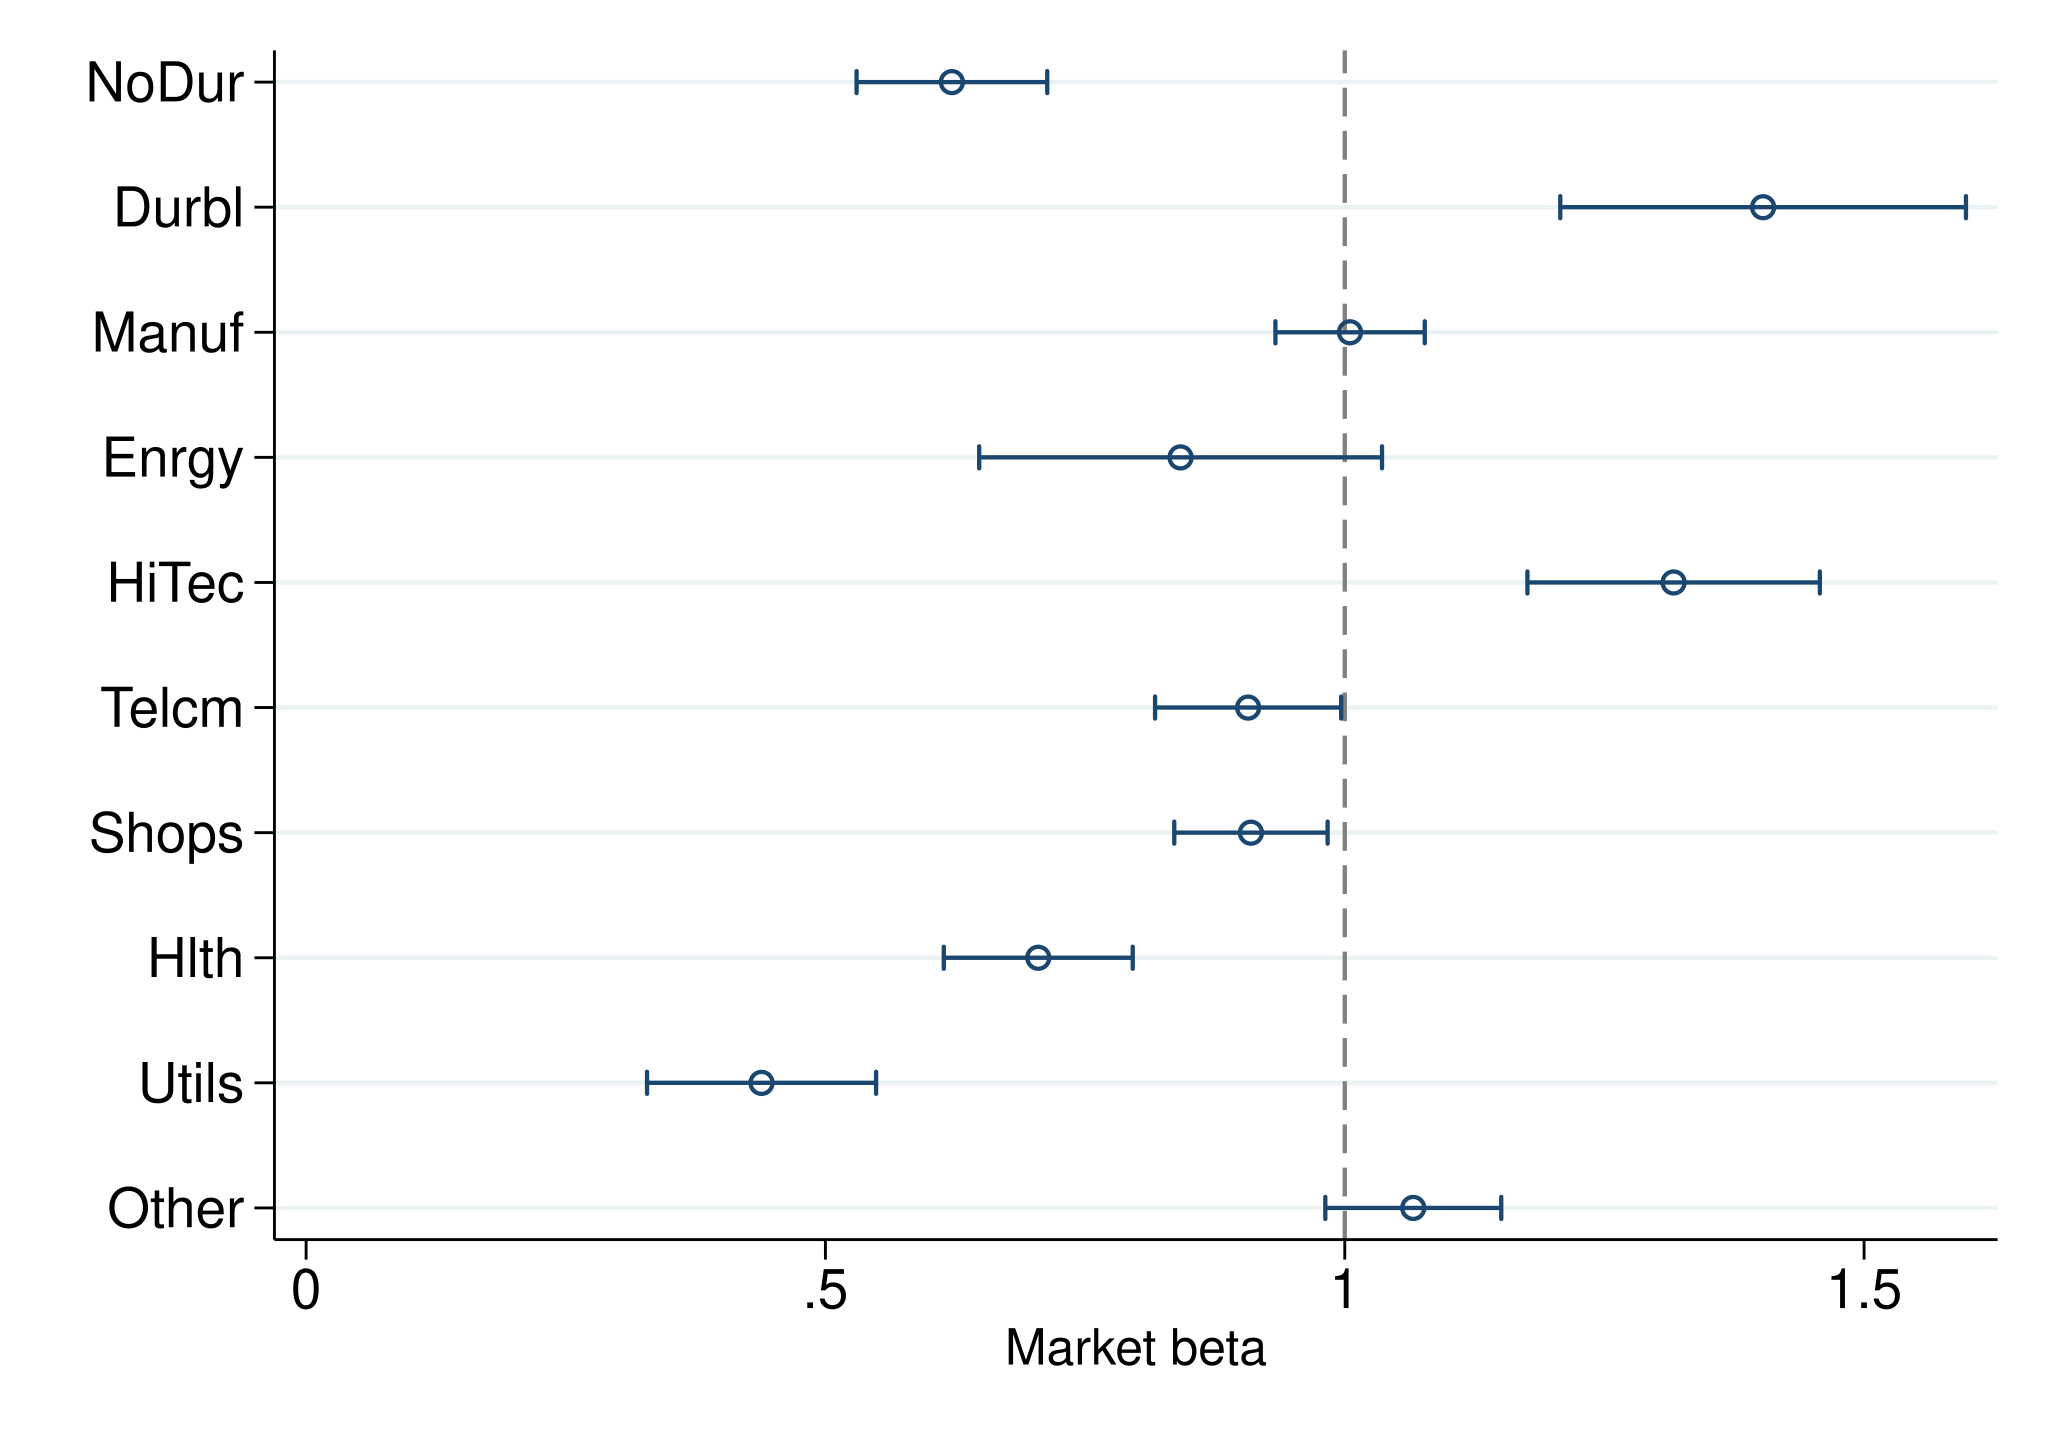

In [5]:
* 循环不改变数据  每个行业均使用同一 432 个月
capture postclose capm_results
postfile capm_results str8 industry double mean double sd ///
    double alpha double beta double se_alpha double se_beta ///
    double alpha_lo double alpha_hi double beta_lo double beta_hi ///
    double p_alpha double p_beta1 double r2 int n ///
    using logs/capm/estimates.dta, replace
foreach a in nodur durbl manuf enrgy hitec telcm shops hlth utils other {
    quietly summarize `a'
    scalar mean_r = r(mean)
    scalar sd_r = r(sd)
    quietly regress ex_`a' mktrf
    scalar fit_r2 = e(r2)
    quietly newey ex_`a' mktrf, lag(6)
    scalar a0 = _b[_cons]
    scalar b0 = _b[mktrf]
    scalar sa = _se[_cons]
    scalar sb = _se[mktrf]
    scalar cv = invttail(e(df_r), .025)
    scalar pa = 2 * ttail(e(df_r), abs(a0 / sa))
    scalar pb = 2 * ttail(e(df_r), abs((b0 - 1) / sb))
    post capm_results ("`a'") (mean_r) (sd_r) (a0) (b0) ///
        (sa) (sb) (a0-cv*sa) (a0+cv*sa) ///
        (b0-cv*sb) (b0+cv*sb) (pa) (pb) (fit_r2) (e(N))
}
postclose capm_results
preserve
use logs/capm/estimates.dta, clear
format mean sd alpha beta se_* %9.4f
list industry mean sd alpha beta se_beta p_alpha r2, noobs
export delimited using logs/capm/estimates.csv, replace
generate row = _n
twoway (rcap beta_lo beta_hi row, horizontal lcolor(navy)) ///
    (scatter row beta, mcolor(navy) msymbol(Oh)), ///
    ylabel(1 "NoDur" 2 "Durbl" 3 "Manuf" 4 "Enrgy" ///
    5 "HiTec" 6 "Telcm" 7 "Shops" 8 "Hlth" ///
    9 "Utils" 10 "Other", angle(0) labsize(medium)) ///
    xlabel(0(.5)1.5, labsize(medium)) ///
    yscale(reverse) ytitle("") xtitle("Market beta") ///
    xline(1, lpattern(dash) lcolor(gs8)) legend(off) ///
    graphregion(color(white)) xsize(6.4) ysize(4.5) ///
    name(betas, replace)
graph export "figs/raw/capm-fig02-betas-${CAPM_STAMP}.png", ///
    replace width(2400)
graph export "figs/raw/capm-fig02-betas-${CAPM_STAMP}.svg", ///
    replace fontface("Times New Roman")
graph export "figs/raw/capm-fig02-betas-${CAPM_STAMP}.pdf", ///
    replace fontface("Times New Roman")
restore



科技行业 $\beta$ 约为 1.317，公用事业行业约为 0.439。它们的原始月均收益分别约为 1.317% 和 0.830%，但截距分别约为每月 0.121% 和 0.282%。$\beta$ 与均值的数字恰好接近，不代表两者具有相同单位或含义。

两行业 $\alpha$ 的 HAC 标准误分别约为 0.184、0.179，双侧检验 $p$ 值约为 0.510、0.115。因此，这组样本与推断设置未在 5% 水平拒绝零截距。公用事业截距点估计较高，不能据此直接断言其具有稳定的超额表现。行业表中的 $R^{2}$ 说明拟合程度，也不检验定价关系。

95% 置信区间采用

$$
\mathrm{CI}_{95}=\widehat{\beta}\pm c\cdot \operatorname{se}(\widehat{\beta}).
$$

这里省略当前行业的下标。$\widehat{\beta}$ 为斜率估计，$\operatorname{se}(\widehat{\beta})$ 为 HAC(6) 标准误，$c$ 为自由度 $T-2=430$ 的 $t$ 分布的 97.5% 分位数；减号和加号分别给出区间下限与上限。$\alpha$ 的区间同理。该推断依赖大样本近似，不保证任意相关误差下的精确小样本覆盖率。

In [6]:
%set graph_height = 3.2in

graph size was (6.4in, 4.5in), is now (6.4in, 3.2in).


## 市场回归图

两幅图横纵坐标口径相同。散点是每月已实现超额收益，拟合线斜率为样本 $\beta$，不是证券市场线。图中所有月份保留，不裁掉极端值。

(note:  named style 0 not found in class margin, default attributes used)
(note:  named style 0 not found in class margin, default attributes used)


(file figs/raw/capm-fig01-market-20261111-155412.png not found)


file figs/raw/capm-fig01-market-20261111-155412.png written in PNG format
(file figs/raw/capm-fig01-market-20261111-155412.svg not found)
file figs/raw/capm-fig01-market-20261111-155412.svg saved as SVG format


file figs/raw/capm-fig01-market-20261111-155412.pdf saved as PDF format


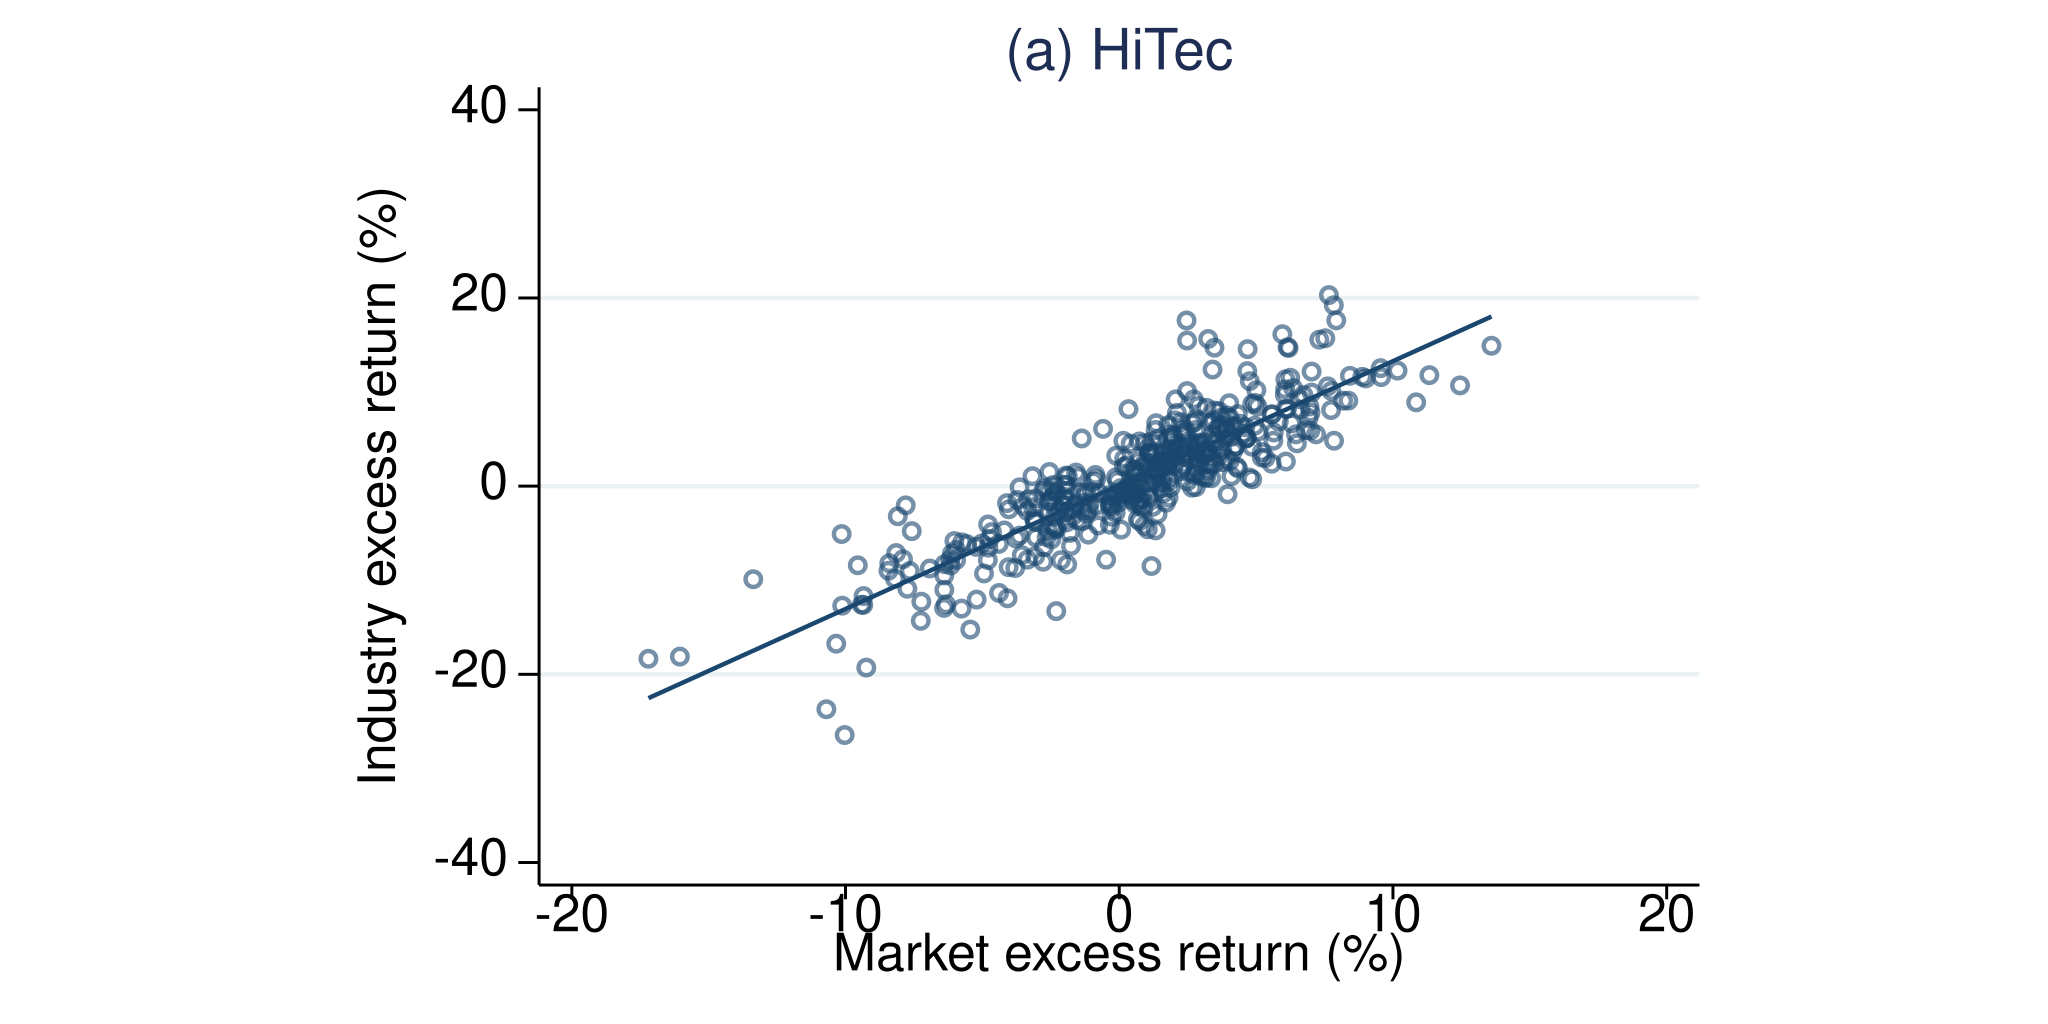

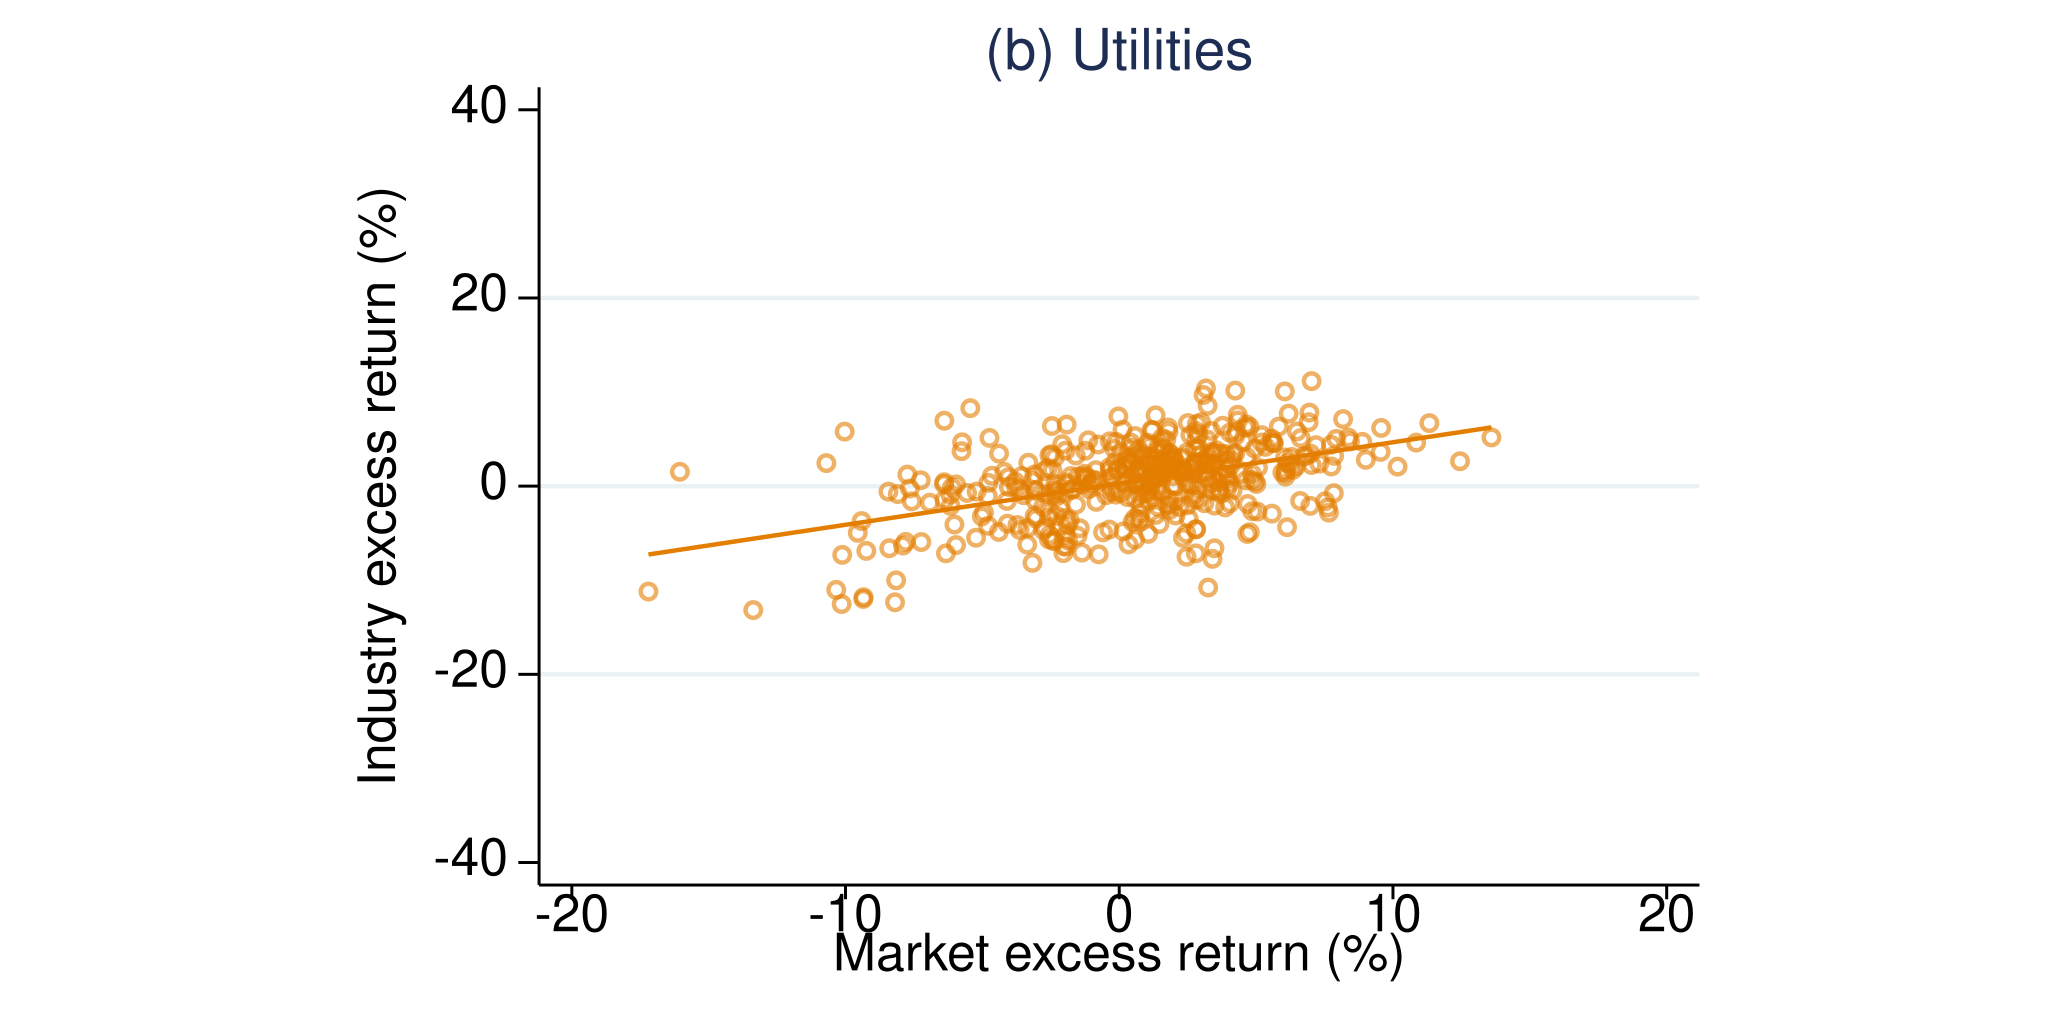

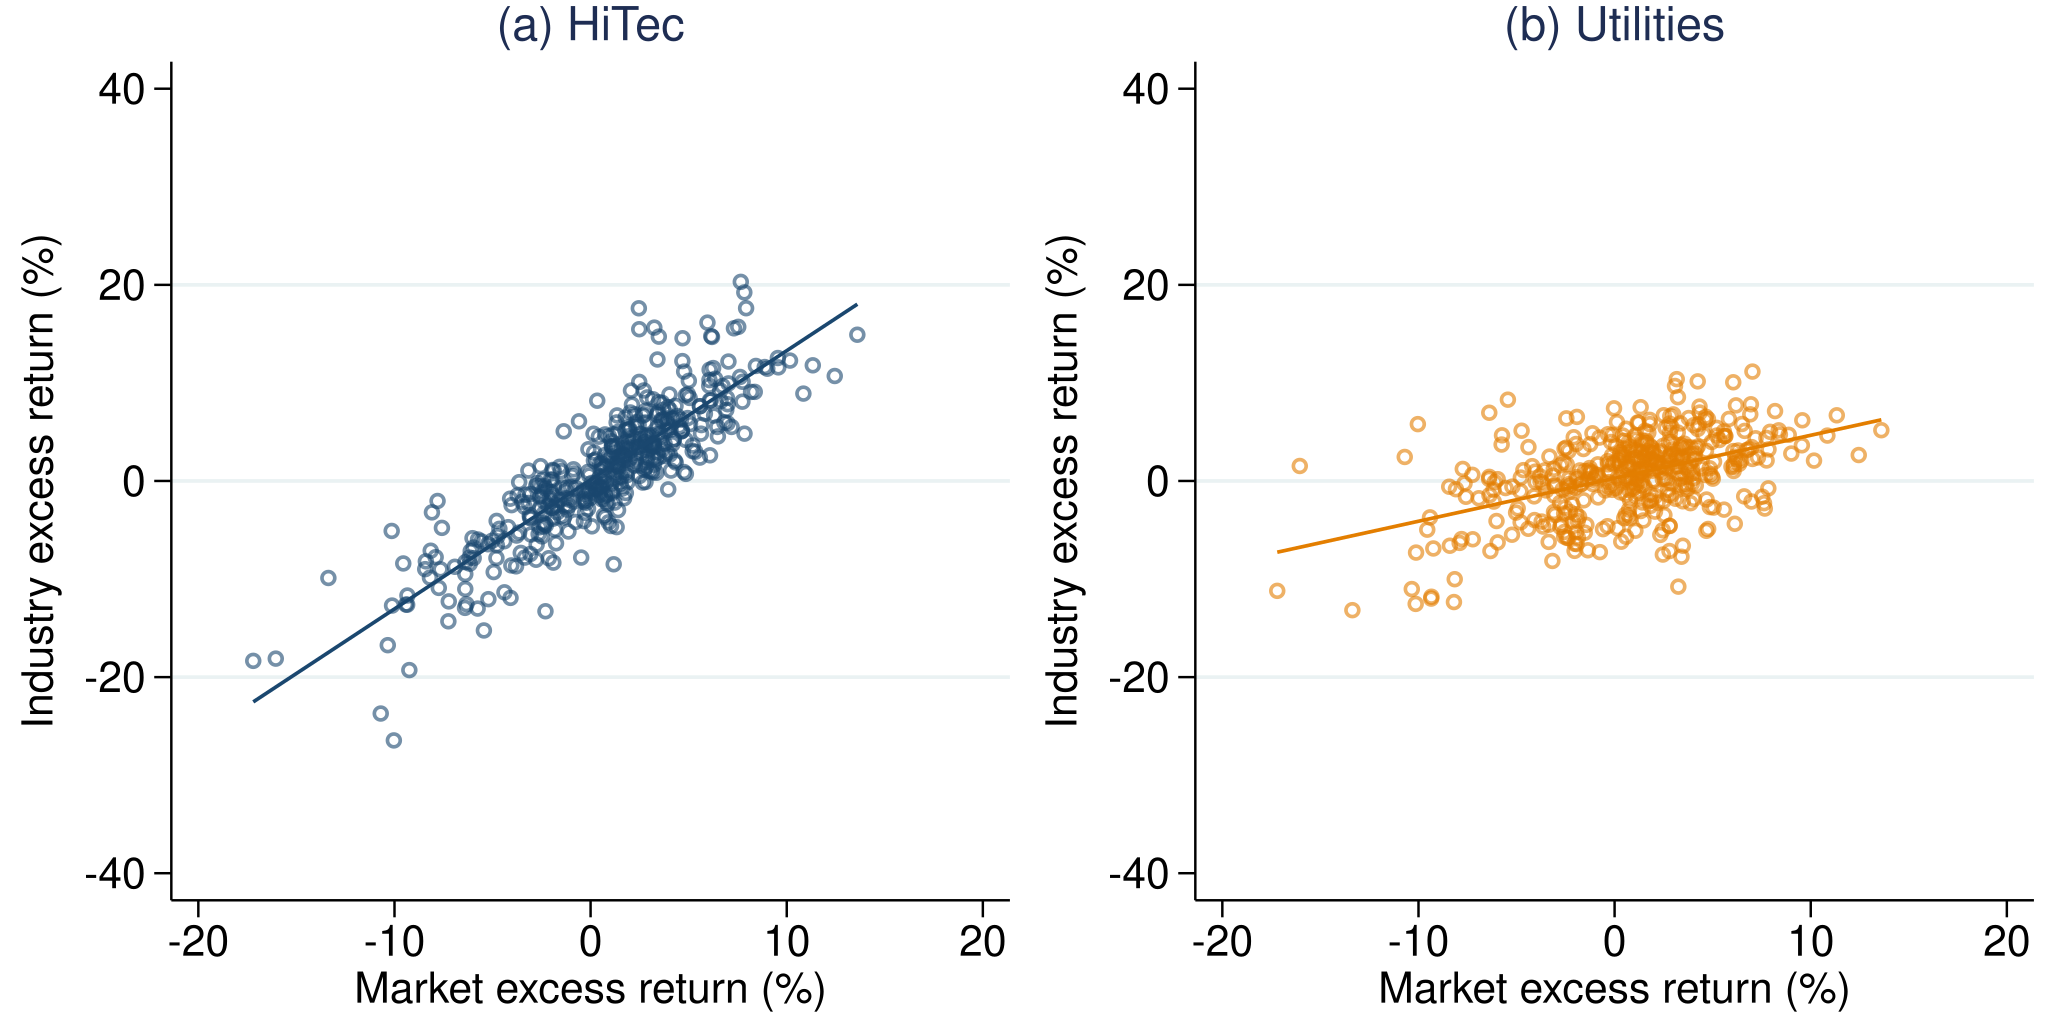

In [7]:
* 两个面板的横纵坐标范围一致  便于比较斜率和离散程度
twoway (scatter ex_hitec mktrf, msymbol(Oh) msize(small) ///
    mlcolor(navy%60) mfcolor(none)) ///
    (lfit ex_hitec mktrf, lcolor(navy)), ///
    title("(a) HiTec", size(medium)) ///
    xtitle("Market excess return (%)") ///
    ytitle("Industry excess return (%)") ///
    xlabel(-20(10)20) ylabel(-40(20)40, angle(0)) ///
    aspectratio(1) legend(off) ///
    graphregion(color(white)) name(hitec, replace)
twoway (scatter ex_utils mktrf, msymbol(Oh) msize(small) ///
    mlcolor(dkorange%60) mfcolor(none)) ///
    (lfit ex_utils mktrf, lcolor(dkorange)), ///
    title("(b) Utilities", size(medium)) ///
    xtitle("Market excess return (%)") ///
    ytitle("Industry excess return (%)") ///
    xlabel(-20(10)20) ylabel(-40(20)40, angle(0)) ///
    aspectratio(1) legend(off) ///
    graphregion(color(white)) name(utils, replace)
graph combine hitec utils, cols(2) xcommon ycommon iscale(1.20) ///
    imargin(0) graphregion(color(white) margin(zero)) ///
    xsize(6.4) ysize(3.2)
graph export "figs/raw/capm-fig01-market-${CAPM_STAMP}.png", ///
    replace width(2800)
graph export "figs/raw/capm-fig01-market-${CAPM_STAMP}.svg", ///
    replace fontface("Times New Roman")
graph export "figs/raw/capm-fig01-market-${CAPM_STAMP}.pdf", ///
    replace fontface("Times New Roman")



## 组合风险

两行业每月各占一半，相当于按月恢复固定权重，尚未扣除交易成本。在线性回归使用同一样本与截距项时，组合 $\beta$ 等于成分 $\beta$ 的加权和。这是线性代数性质，不是 CAPM 定价关系成立的独立证据。

In [8]:
* 固定权重的线性恒等式不是 CAPM 的独立验证
quietly regress ex_hitec mktrf
scalar bh = _b[mktrf]
quietly regress ex_utils mktrf
scalar bu = _b[mktrf]
generate double ex_portfolio = .5*ex_hitec + .5*ex_utils
regress ex_portfolio mktrf
scalar beta_gap = _b[mktrf] - (.5*bh + .5*bu)
display "固定权重组合 beta 的代数误差 = " %16.12f beta_gap
assert abs(beta_gap) < 1e-10




      Source |       SS           df       MS      Number of obs   =       4
> 32
-------------+----------------------------------   F(1, 430)       =   1765.
> 92
       Model |  6395.23401         1  6395.23401   Prob > F        =    0.00
> 00
    Residual |  1557.23799       430  3.62148369   R-squared       =    0.80
> 42
-------------+----------------------------------   Adj R-squared   =    0.80
> 37
       Total |    7952.472       431  18.4512111   Root MSE        =     1.9
> 03

----------------------------------------------------------------------------
> --
ex_portfolio | Coefficient  Std. err.      t    P>|t|     [95% conf. interva
> l]
-------------+--------------------------------------------------------------
> --
       mktrf |      0.878      0.021    42.02   0.000        0.837       0.9
> 19
       _cons |      0.202      0.093     2.17   0.030        0.019       0.3
> 84
----------------------------------------------------------------------------
> --
固定权重组合 beta 的代

In [9]:
%set graph_height = 3.2in

## 滚动估计

先以 2025 年 12 月为目标月，显示只使用此前 60 个月的单次回归；随后循环构造两条序列。目标月 $t$ 的 $\beta$ 只用此前 36 或 60 个月。两窗口统一从 1995 年 1 月开始比较，末次输入为 $t-1$。窗口重叠造成相邻估计相关，曲线波动不能独自证明真实 $\beta$ 在变。

(Note: Below code run with echo to enable preserve/restore functionality.)




      Source |       SS           df       MS      Number of obs   =        
> 60
-------------+----------------------------------   F(1, 58)        =    265.
> 97
       Model |  1646.52388         1  1646.52388   Prob > F        =    0.00
> 00
    Residual |   359.05314        58  6.19057137   R-squared       =    0.82
> 10
-------------+----------------------------------   Adj R-squared   =    0.81
> 79
       Total |  2005.57702        59  33.9928308   Root MSE        =    2.48
> 81

----------------------------------------------------------------------------
> --
    ex_hitec | Coefficient  Std. err.      t    P>|t|     [95% conf. interva
> l]
-------------+--------------------------------------------------------------
> --
       mktrf |      1.187      0.073    16.31   0.000        1.042       1.3
> 33
       _cons |      0.300      0.329     0.91   0.365       -0.358       0.9
> 58
------------------


file logs/capm/rolling.csv saved



(note:  named style 0 not found in class margin, default attributes used)
(note:  named style 0 not found in class margin, default attributes used)



(file figs/raw/capm-fig03-rolling-20261111-155412.png not found)


file figs/raw/capm-fig03-rolling-20261111-155412.png written in PNG format

(file figs/raw/capm-fig03-rolling-20261111-155412.svg not found)
file figs/raw/capm-fig03-rolling-20261111-155412.svg saved as SVG format

file figs/raw/capm-fig03-rolling-20261111-155412.pdf saved as PDF format


  +---------------------------------------------------+
  | industry   window    mdate   end_used        beta |
  |---------------------------------------------------|
  |    hitec       36   1995m1    1994m12   1.2930961 |
  |    hitec       36   1995m2     1995m1   1.2921635 |
  |    hitec       36   1995m3     1995m2   1.3049862 |
  |    hitec       36   1995m4     1995m3   1.2747823 |
  +---------------------------------------------------+





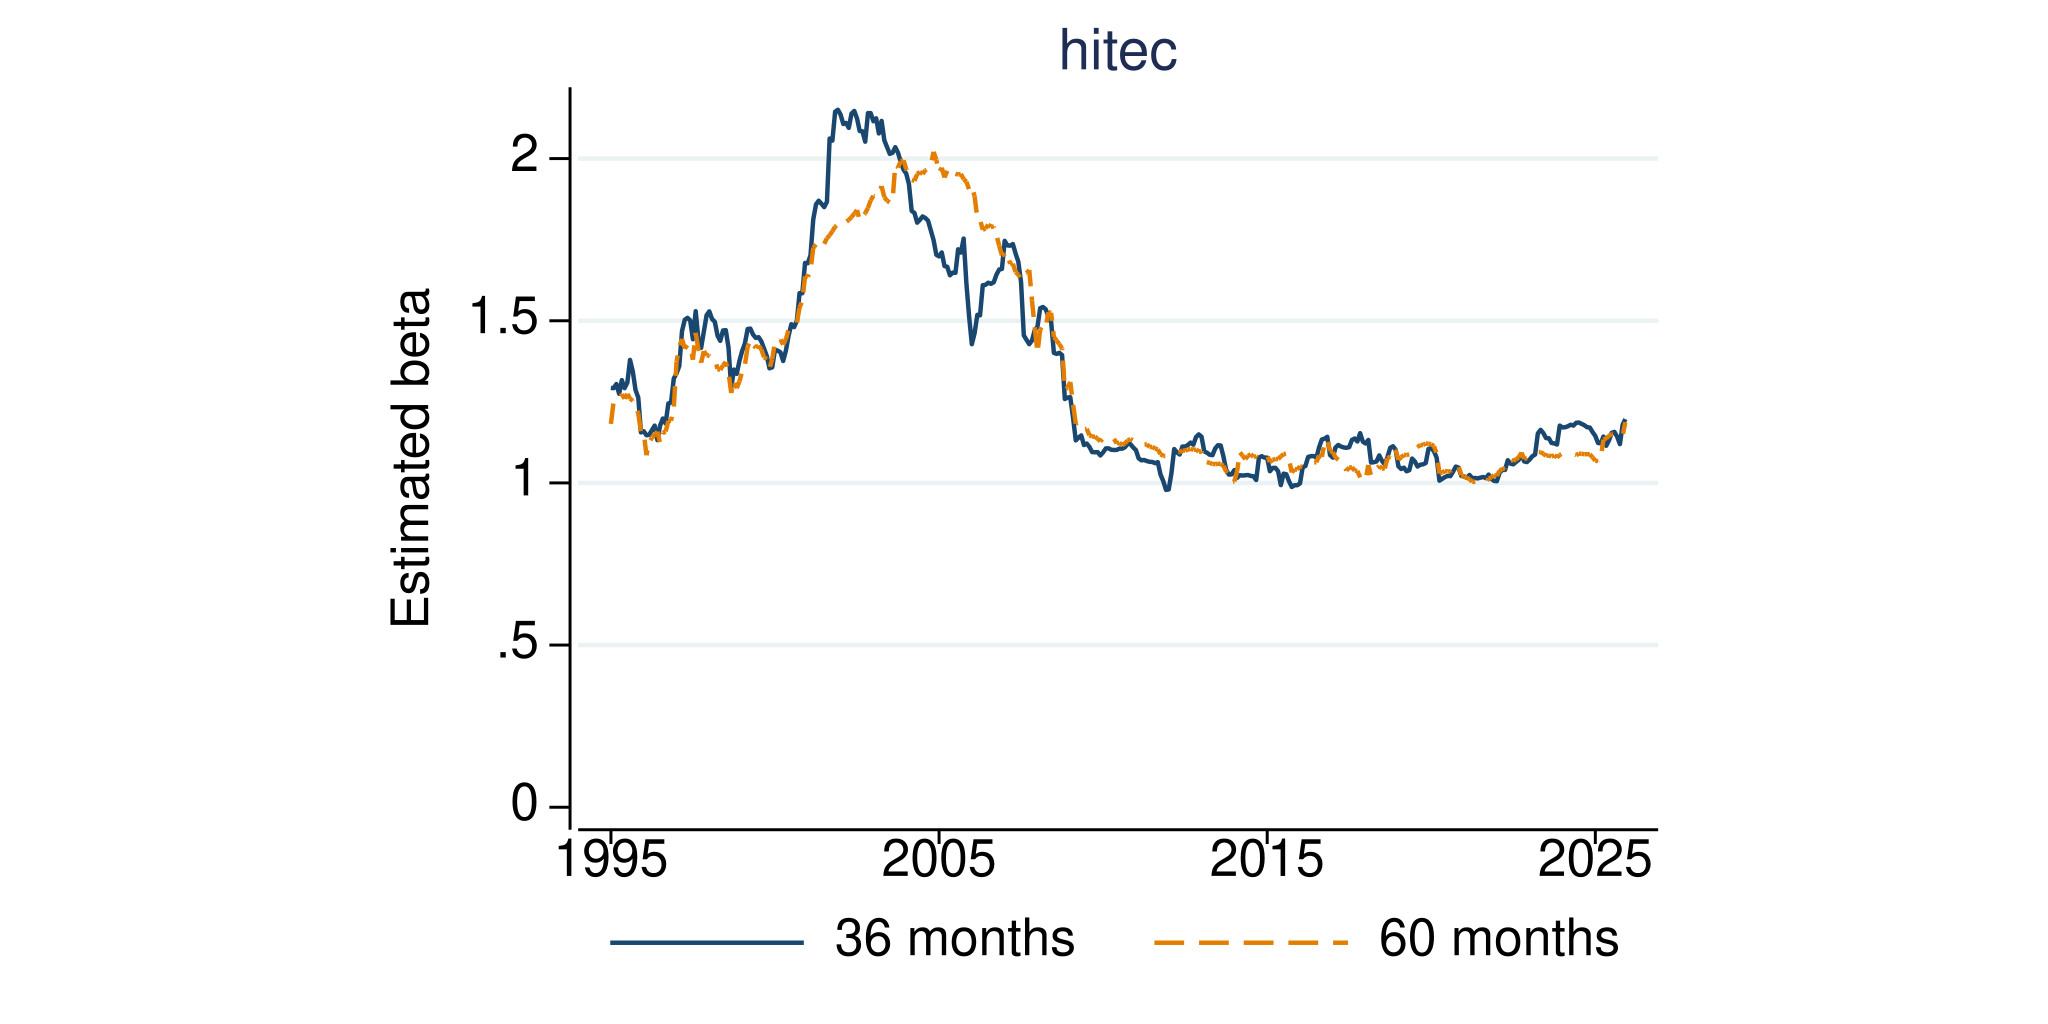

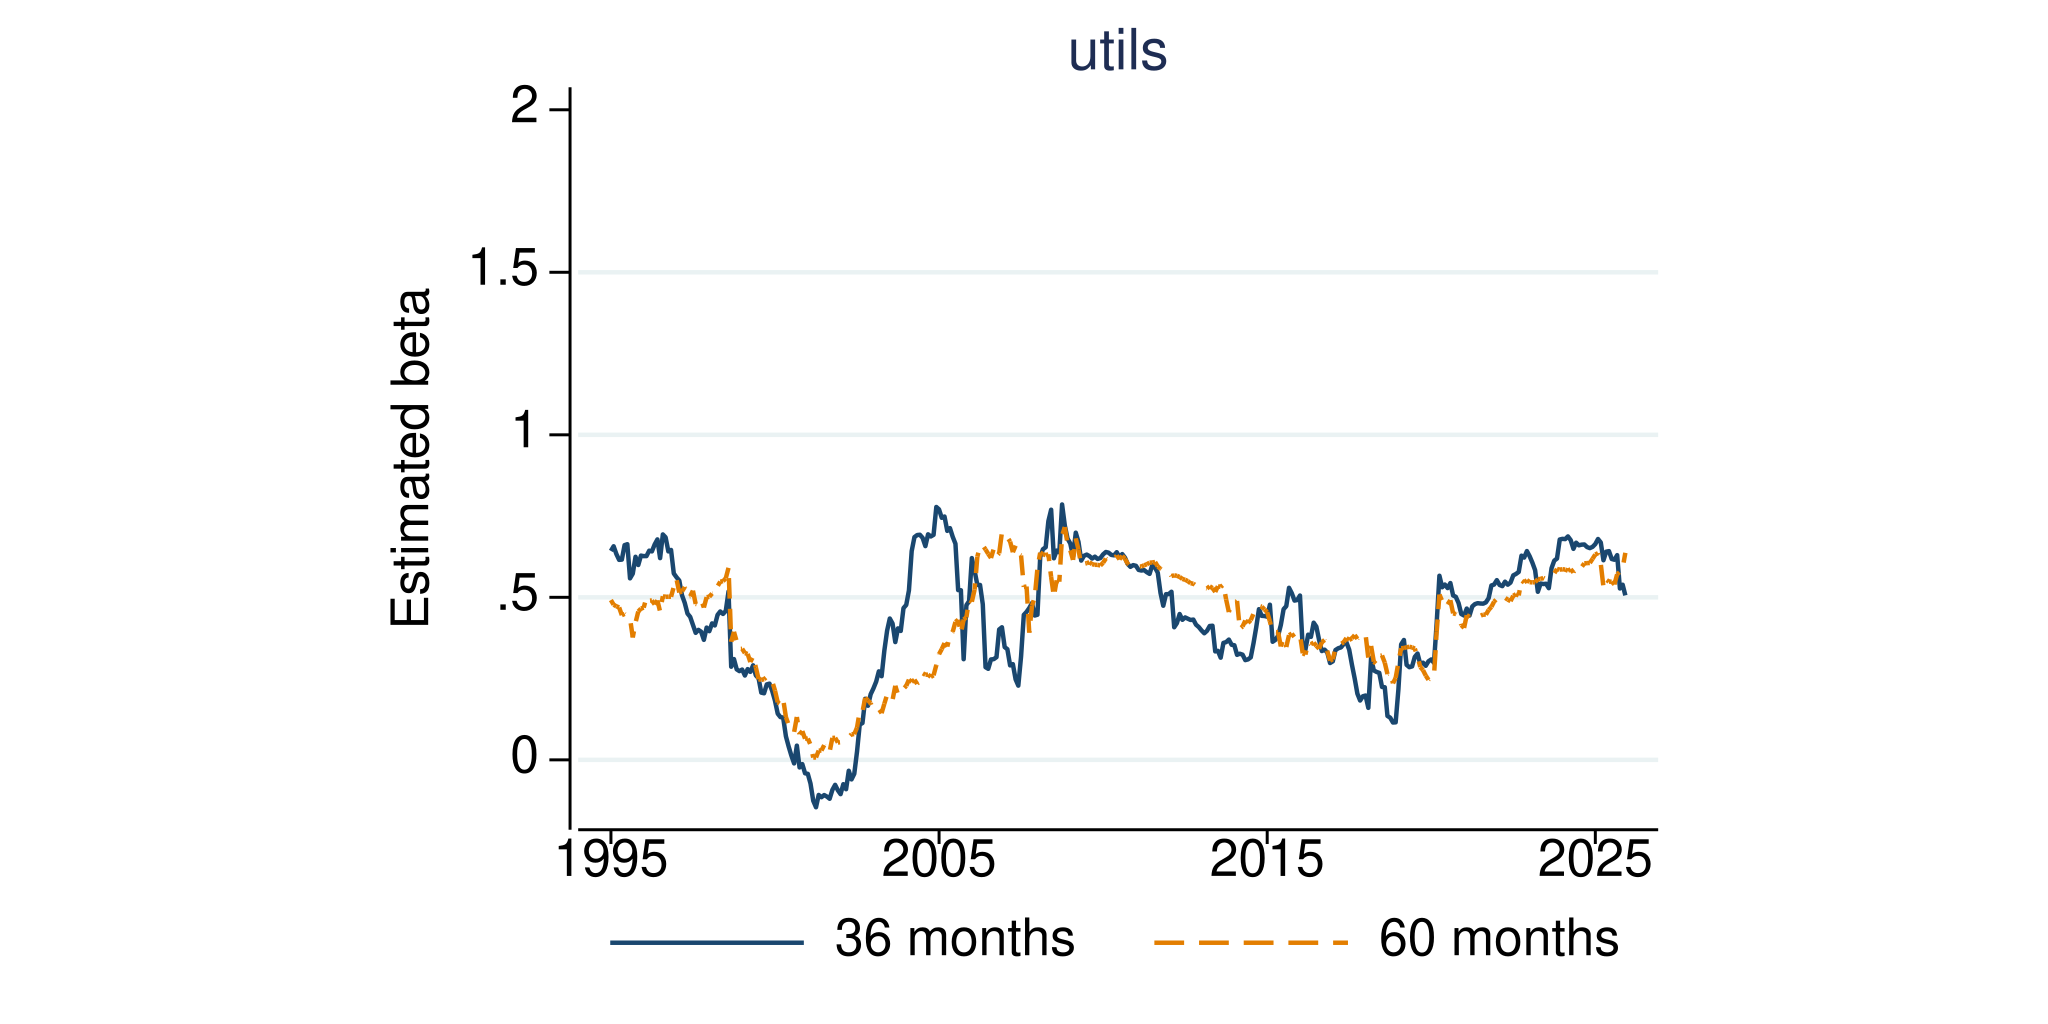

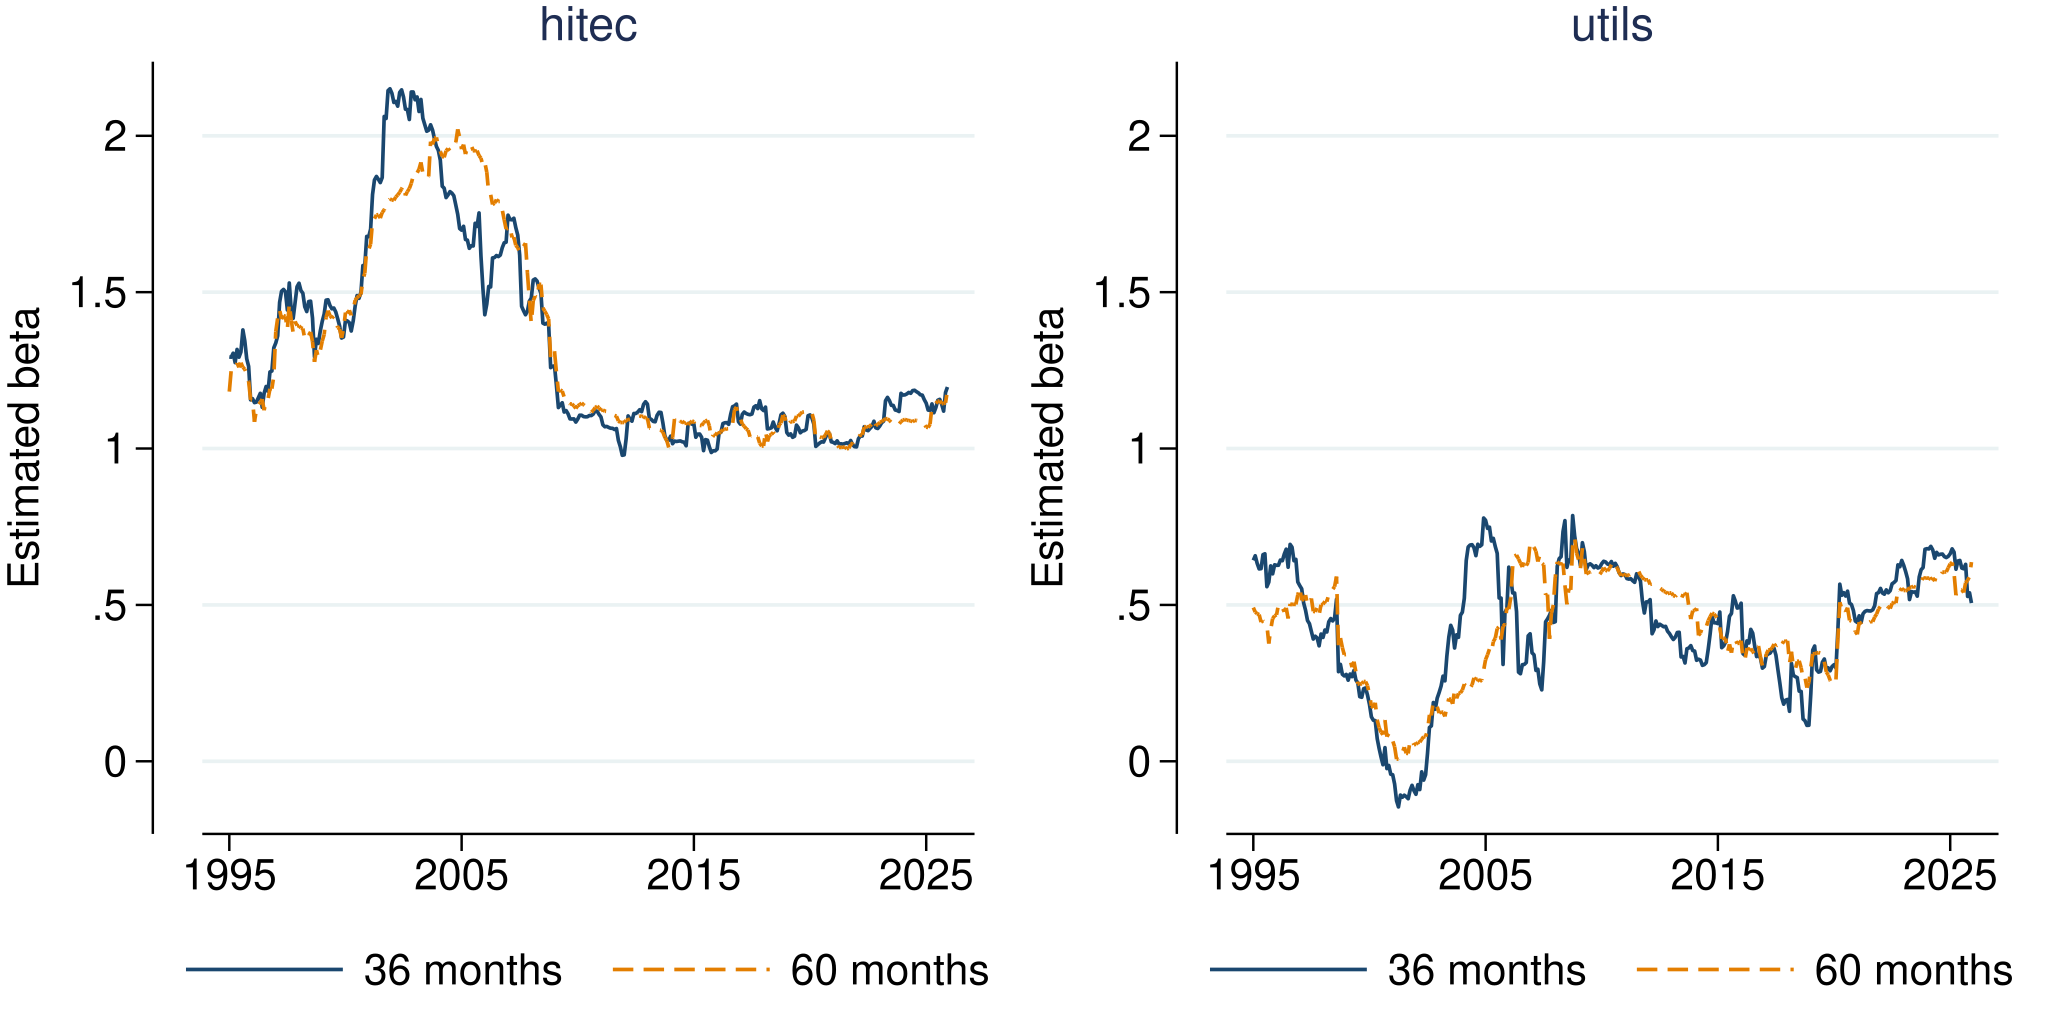

In [10]:
* 目标月份为 i  只使用 i-window 至 i-1 的已观察收益
* 单个月份先核验  命令无需在 76 列以内另起续行
local t = tm(2025m12)
regress ex_hitec mktrf if inrange(mdate, `t'-60, `t'-1)
display "beta = " %7.3f _b[mktrf]
capture postclose capm_roll
postfile capm_roll str8 industry int window mdate end_used ///
    double beta using logs/capm/rolling.dta, replace
foreach a in hitec utils {
    foreach w in 36 60 {
        forvalues i = 61/432 {
            local first = `i' - `w'
            local last = `i' - 1
            quietly regress ex_`a' mktrf in `first'/`last'
            post capm_roll ("`a'") (`w') (mdate[`i']) ///
                (mdate[`last']) (_b[mktrf])
        }
    }
}
postclose capm_roll
preserve
use logs/capm/rolling.dta, clear
format mdate end_used %tm
assert end_used == mdate - 1
assert _N == 1488
sort industry window mdate
export delimited using logs/capm/rolling.csv, replace
foreach a in hitec utils {
    twoway (line beta mdate if industry=="`a'" & window==36, ///
        lcolor(navy) lpattern(solid)) ///
        (line beta mdate if industry=="`a'" & window==60, ///
        lcolor(dkorange) lpattern(dash)), ///
        title("`a'", size(medium)) xtitle("") ///
        ytitle("Estimated beta") ylabel(0(.5)2, angle(0)) ///
        xlabel(420 540 660 780, format(%tmCCYY)) ///
        legend(order(1 "36 months" 2 "60 months") rows(1) ///
        region(lstyle(none))) ///
        aspectratio(1) graphregion(color(white)) ///
        name(roll_`a', replace)
}
graph combine roll_hitec roll_utils, cols(2) ycommon iscale(1.20) ///
    imargin(0) graphregion(color(white) margin(zero)) ///
    xsize(6.4) ysize(3.2)
graph export "figs/raw/capm-fig03-rolling-${CAPM_STAMP}.png", ///
    replace width(2800)
graph export "figs/raw/capm-fig03-rolling-${CAPM_STAMP}.svg", ///
    replace fontface("Times New Roman")
graph export "figs/raw/capm-fig03-rolling-${CAPM_STAMP}.pdf", ///
    replace fontface("Times New Roman")
list in 1/4, noobs
restore



In [11]:
%set graph_height = 3.2in

## 参数变化与估计噪声

读取固定文件 beta_sim.dta。数据在首次生成时包含 240 个月的模拟市场超额收益 $x=0.5+4z$，随机干扰项 $u=4v$，$z$、$v$ 独立标准正态。第一条序列 $\alpha=0$、$\beta=1$ 始终固定；第二条 $\beta$ 前 120 月为 1，之后为 1.8。每次演示只读取固定文件；两条序列共用 $x$ 和 $u$，只改变斜率规则。滚动估计均只用过去 60 月。真实参数已知，便于分辨估计波动与参数变化；这不是实际市场的历史结果。

file logs/capm/simulation-input.dta saved
file logs/capm/simulation-input.csv saved


file logs/capm/simulation.csv saved


(note:  named style 0 not found in class margin, default attributes used)
(note:  named style 0 not found in class margin, default attributes used)


(file figs/raw/capm-fig04-simulation-20261111-155412.png not found)


file figs/raw/capm-fig04-simulation-20261111-155412.png written in PNG forma
> t
(file figs/raw/capm-fig04-simulation-20261111-155412.svg not found)


file figs/raw/capm-fig04-simulation-20261111-155412.svg saved as SVG
    format
file figs/raw/capm-fig04-simulation-20261111-155412.pdf saved as PDF
    format

    Variable |        Obs        Mean    Std. dev.       Min        Max
-------------+---------------------------------------------------------
     b_fixed |        180    .9186673    .1343704   .6070185   1.193304
    b_change |        180    1.303332    .2627182   .8844001   1.661002
CAPM 运行完成 模拟与真实数据的输出分别保存


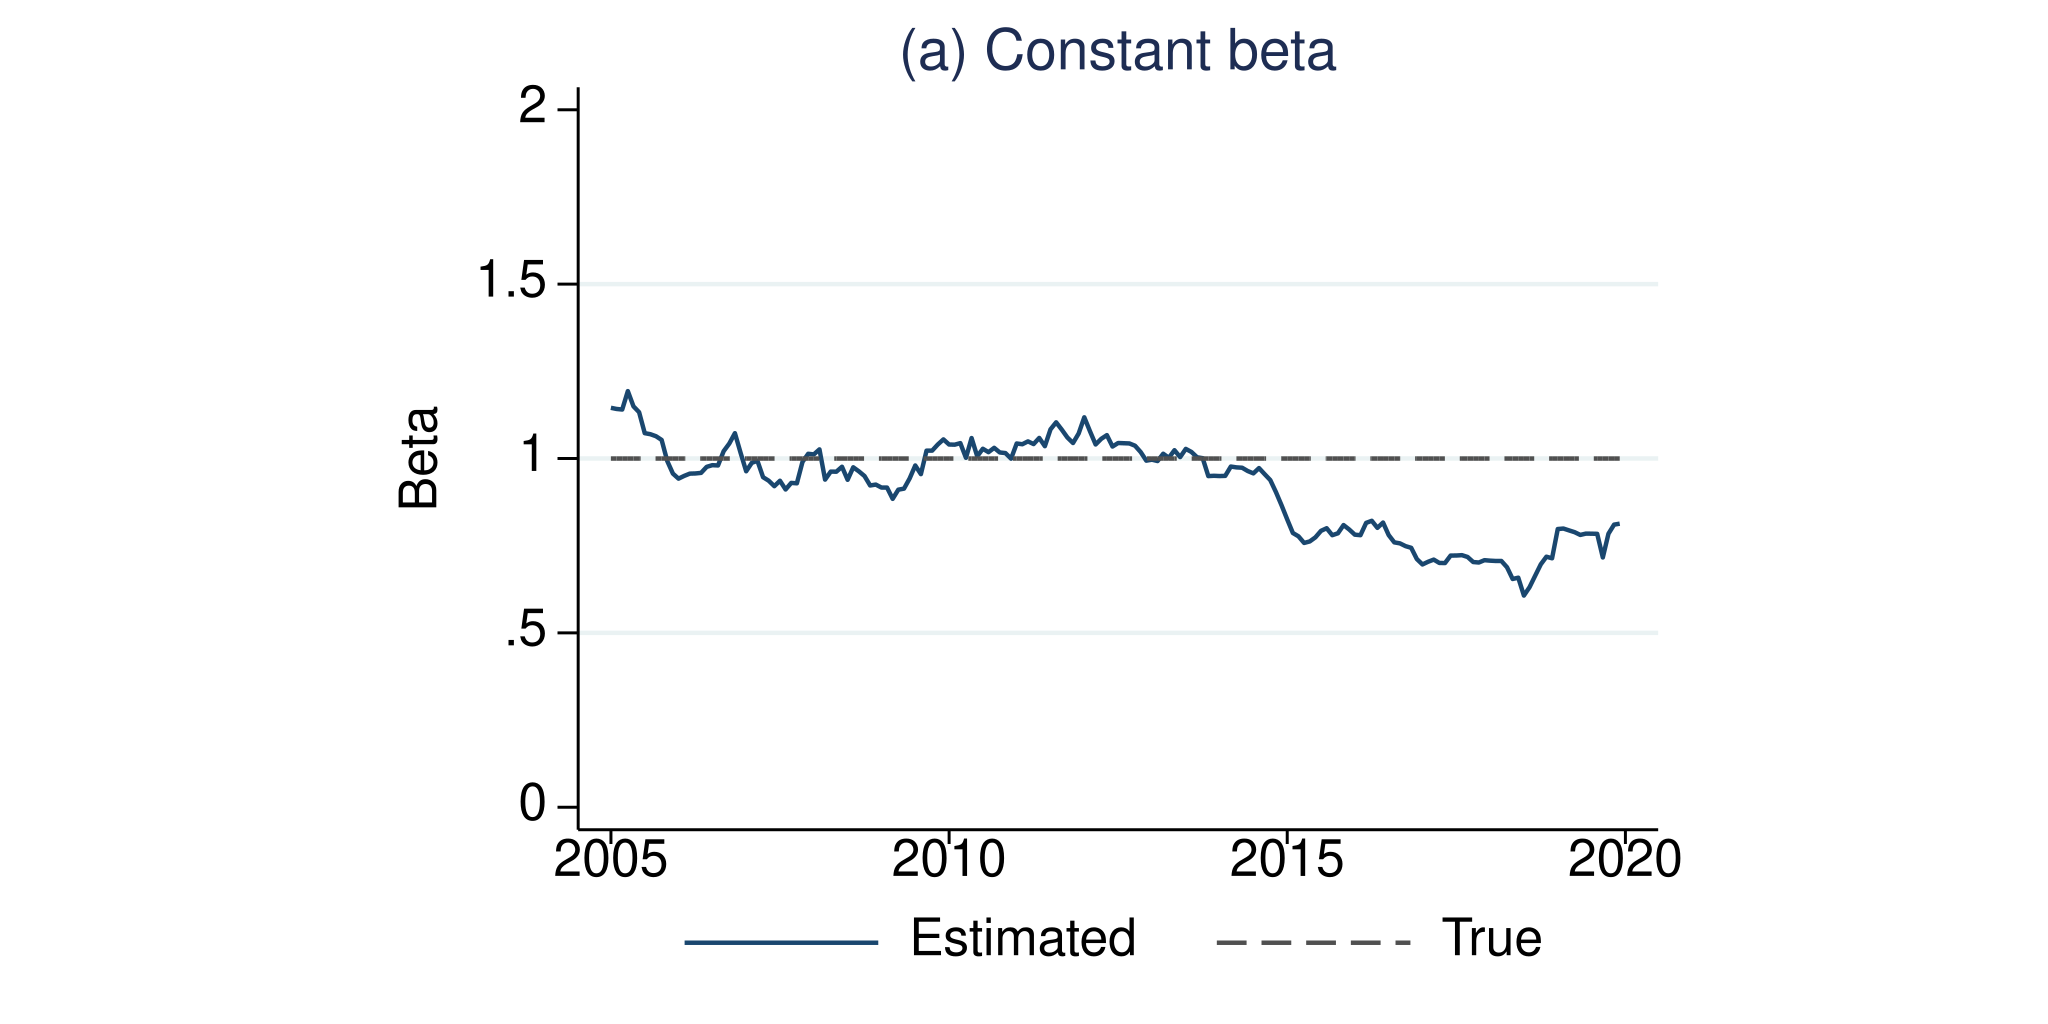

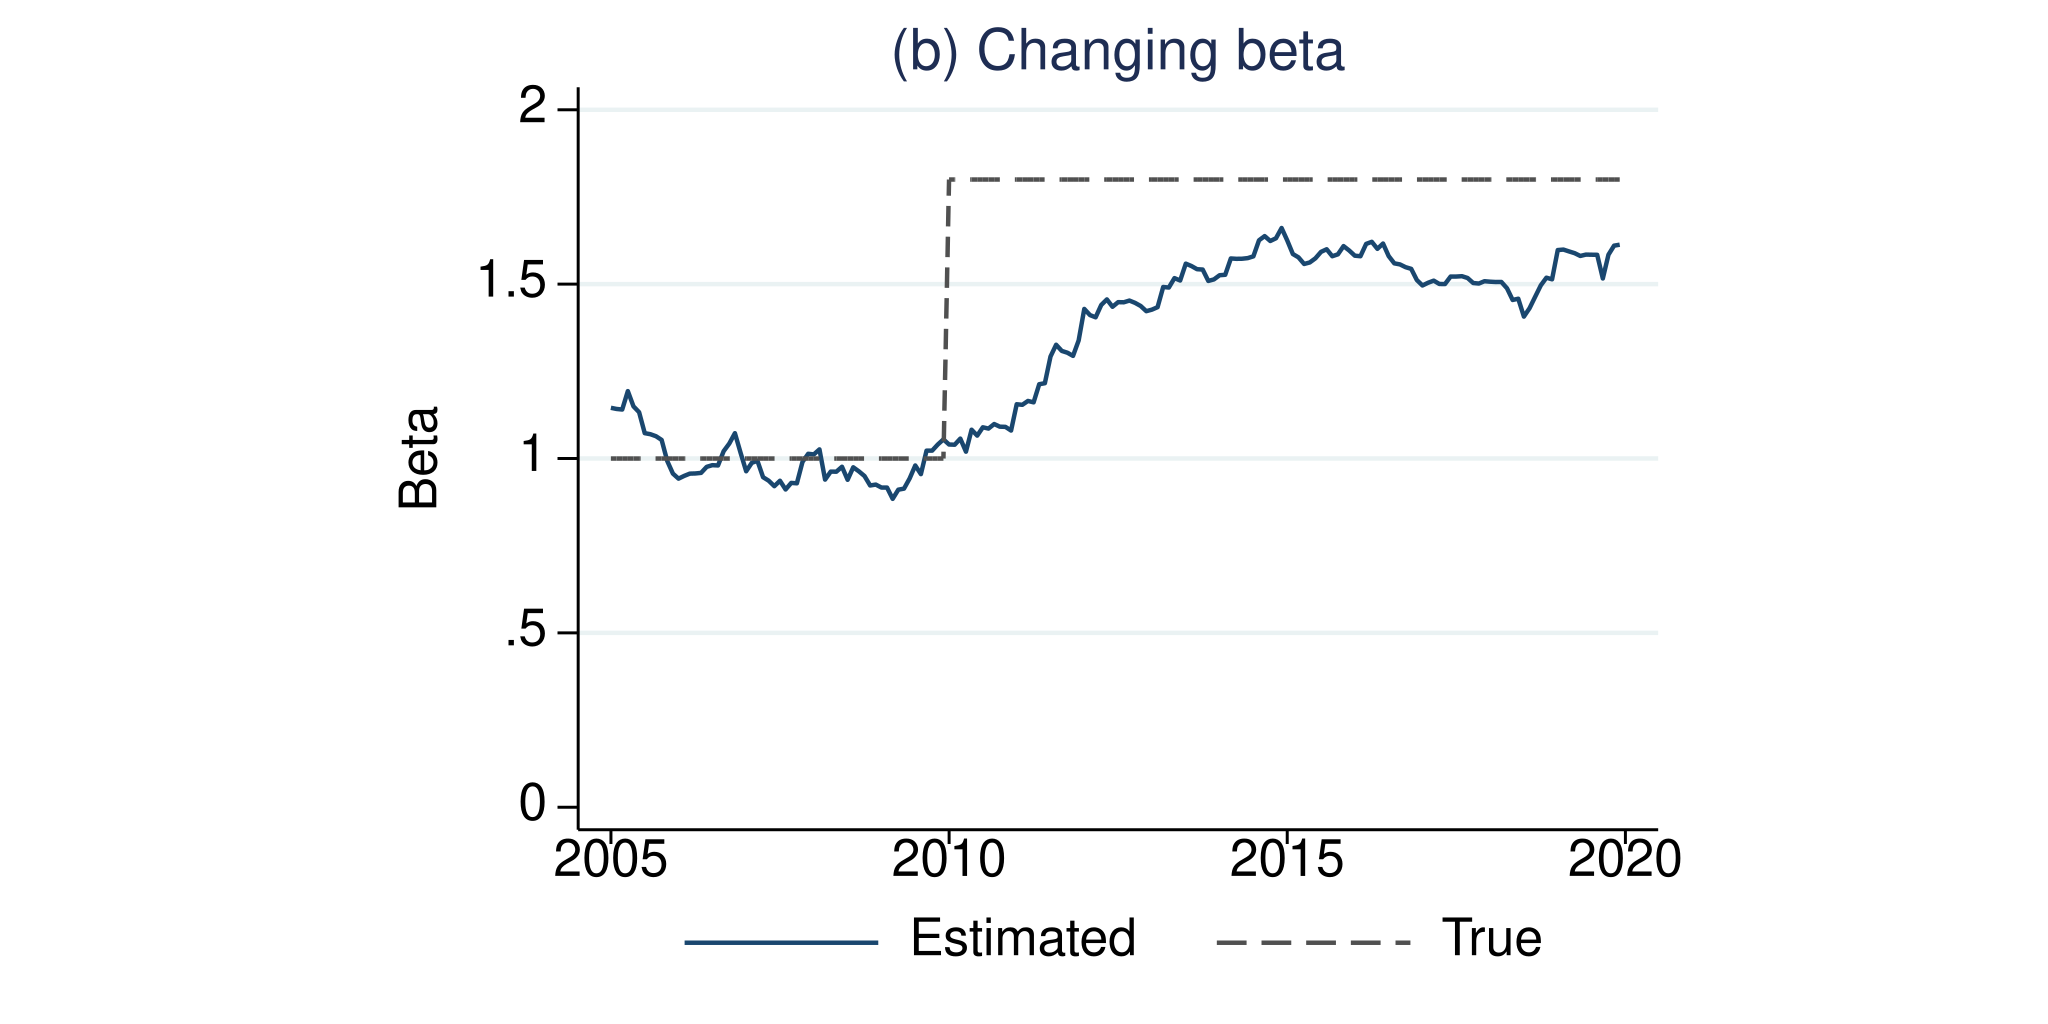

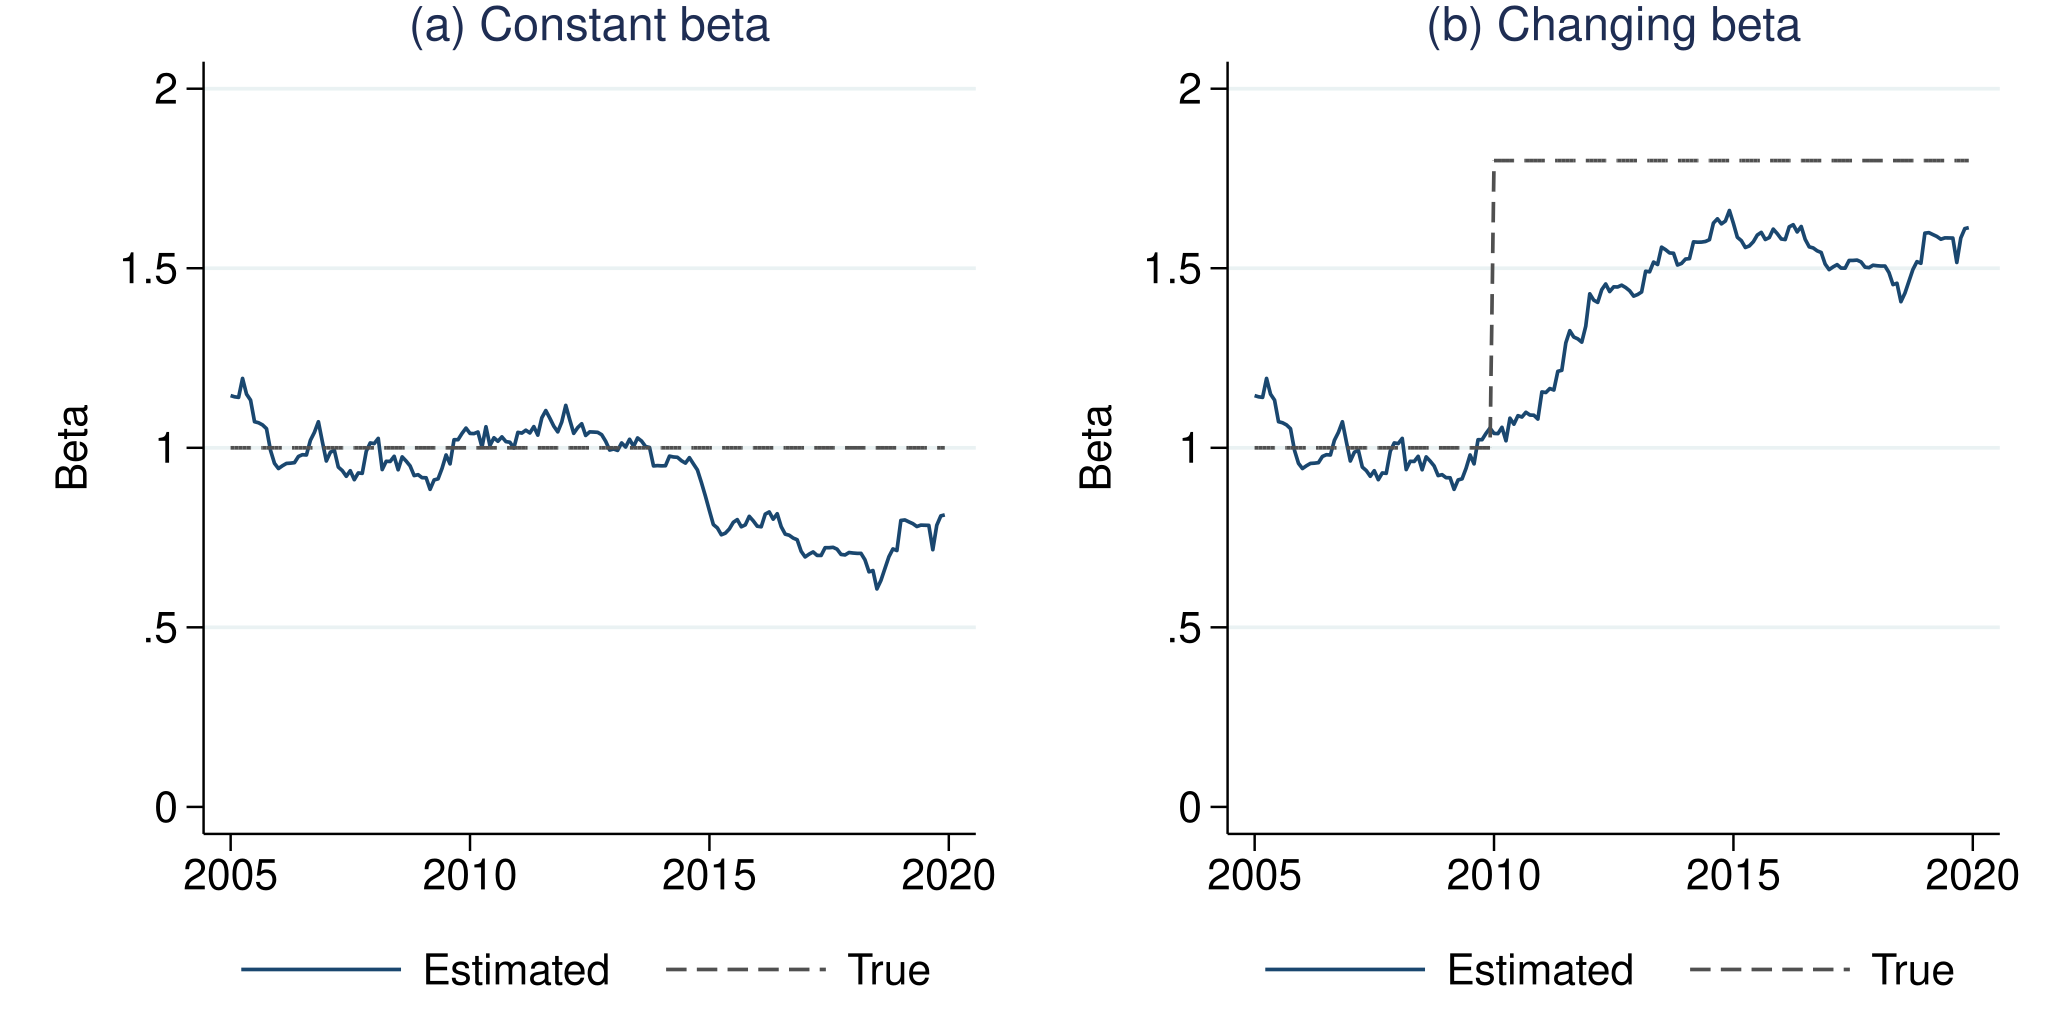

In [12]:
* 同一市场收益和扰动  只改变 beta 的生成规则
use data/capm/beta_sim.dta, clear
format mdate %tm
assert _N == 240
assert mdate == tm(2000m1) + _n - 1
save logs/capm/simulation-input.dta, replace
export delimited using logs/capm/simulation-input.csv, replace
capture postclose capm_sim
postfile capm_sim int mdate double b_fixed double b_change ///
    double beta_true ///
    using logs/capm/simulation.dta, replace
forvalues i = 61/240 {
    local first = `i' - 60
    local last = `i' - 1
    quietly regress ex_fixed mktrf in `first'/`last'
    scalar bf = _b[mktrf]
    quietly regress ex_change mktrf in `first'/`last'
    post capm_sim (mdate[`i']) (bf) (_b[mktrf]) (beta_true[`i'])
}
postclose capm_sim
use logs/capm/simulation.dta, clear
format mdate %tm
generate fixed_true = 1
assert _N == 180
export delimited using logs/capm/simulation.csv, replace
twoway (line b_fixed mdate, lcolor(navy)) ///
    (line fixed_true mdate, lcolor(gs5) lpattern(dash)), ///
    title("(a) Constant beta", size(medium)) ///
    ytitle("Beta") xtitle("") ylabel(0(.5)2, angle(0)) ///
    xlabel(540 600 660 720, format(%tmCCYY)) ///
    legend(order(1 "Estimated" 2 "True") rows(1) ///
    region(lstyle(none))) ///
    aspectratio(1) graphregion(color(white)) ///
    name(sim_fixed, replace)
twoway (line b_change mdate, lcolor(navy)) ///
    (line beta_true mdate, lcolor(gs5) lpattern(dash)), ///
    title("(b) Changing beta", size(medium)) ///
    ytitle("Beta") xtitle("") ylabel(0(.5)2, angle(0)) ///
    xlabel(540 600 660 720, format(%tmCCYY)) ///
    legend(order(1 "Estimated" 2 "True") rows(1) ///
    region(lstyle(none))) ///
    aspectratio(1) graphregion(color(white)) ///
    name(sim_change, replace)
graph combine sim_fixed sim_change, cols(2) ycommon iscale(1.20) ///
    imargin(0) graphregion(color(white) margin(zero)) ///
    xsize(6.4) ysize(3.2)
graph export "figs/raw/capm-fig04-simulation-${CAPM_STAMP}.png", ///
    replace width(2800)
graph export "figs/raw/capm-fig04-simulation-${CAPM_STAMP}.svg", ///
    replace fontface("Times New Roman")
graph export "figs/raw/capm-fig04-simulation-${CAPM_STAMP}.pdf", ///
    replace fontface("Times New Roman")
summarize b_fixed b_change
display "CAPM 运行完成  模拟与真实数据的输出分别保存"


左图真值始终为 1，估计仍约在 0.607 至 1.193 之间变化。这是固定参数下的一条模拟路径，说明滚动曲线波动可以由估计噪声产生；它不是所有模型下误差范围的一般结论。

右图真值在第 121 月跳到 1.8。目标月只用过去 60 月估计，旧状态观测逐步退出窗口，因此估计对变化有滞后。日期从 2000 年开始仅为展示时间轴，不对应真实市场事件。真实行业数据没有可直接观察的 $\beta$ 真值，不能仅凭曲线把参数变化和估计噪声区分开。

## 习题

回到行业表，分别用均值、波动、$\beta$、$\alpha$ 区间和 $R^{2}$ 写出一句有明确口径的判断。$\beta$ 不衡量全部风险，$\alpha$ 的解释依赖市场代理、样本与模型。$\alpha$ 不显著不等于模型已被证明。

固定模型与样本，改变 HAC 最大滞后；再固定数据，改变滚动窗口。运行前先说明预计哪些结果不变，哪些可能变化。模拟中真值已知，真实行业数据中真值未知。

## 文献联系

1. Fama and French ([1992](https://doi.org/10.1111/j.1540-6261.1992.tb04398.x)) 研究了股票平均收益差异。在其 1963—1990 年样本与检验设计下，市场 $\beta$ 的解释力很弱，规模和账面市值比则能共同解释主要差异。其组合 $\beta$ 用于个股横截面定价检验，不是历史时点均可获得的风险预测。
2. Baker et al. ([2011](https://doi.org/10.2469/faj.v67.n1.4)) 发现了低波动、低 $\beta$ 组合相对高风险组合的收益优势，并用风险偏好和基准考核约束提出解释。历史收益证据与解释机制应分别理解。
3. Frazzini and Pedersen ([2014](https://doi.org/10.1016/j.jfineco.2013.10.005)) 用事前 $\beta$ 调整多空规模，构建近似市场中性的 BAB 因子，发现其具有正的风险调整收益，且在融资条件收紧时表现较差。$\beta$ 的估计直接影响头寸规模。
4. Ang and Chen ([2007](https://doi.org/10.1016/j.jempfin.2005.12.001)) 估计了长期样本中的条件 CAPM，发现所设定模型下价值策略的条件 $\alpha$ 缺乏显著异于零的证据。该推断依赖完整条件模型，不等于简单滚动 OLS。
5. Gormsen and Jensen ([2024](https://doi.org/10.1016/j.jfineco.2024.103933)) 发现条件风险能够解释多项股票策略的部分无条件 $\alpha$，但仍不足以解释全部异常收益，条件 CAPM 仍被拒绝。
6. Drobetz et al. ([2025](https://doi.org/10.1017/S0022109024000036)) 发现机器学习 $\beta$ 预测在统计和投资组合应用中优于所比较的传统基准，其中随机森林总体最好；非线性和交互关系有助于预测。

这些是不同研究用途的例子，本实验没有复现六篇论文的完整设计。完整文献信息见理论讲义；输入与处理见数据说明。不要将本例行业结果外推为 A 股个股结论。
